In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

project_root = Path.cwd().parent
data_path = (
    project_root
    / "data"
    / "processed"
    / "apl_logistics_cleaned.csv"
)

df = pd.read_csv(data_path)

print("Discount Impact Analysis")
print("Dataset loaded:", not df.empty)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Discount Impact Analysis
Dataset loaded: True
Rows: 180519
Columns: 40


In [2]:
df["Discount_Band"] = pd.cut(
    df["Order Item Discount Rate"],
    bins=[-0.001, 0.05, 0.10, 0.20, 1.0],
    labels=["0–5%", "5–10%", "10–20%", "20%+"],
    include_lowest=True
)

discount_summary = df.groupby(
    "Discount_Band",
    observed=False
).agg(
    Transaction_Rows=("Order Item Total", "count"),
    Total_Net_Sales=("Order Item Total", "sum"),
    Total_Profit=("Order Profit Per Order", "sum"),
    Total_Discounts=("Order Item Discount", "sum")
).reset_index()

discount_summary["Profit_Margin_Percent"] = (
    discount_summary["Total_Profit"]
    / discount_summary["Total_Net_Sales"]
) * 100

display(discount_summary.round(2))

,Discount_Band,Transaction_Rows,Total_Net_Sales,Total_Profit,Total_Discounts,Profit_Margin_Percent
0,0–5%,60171,11951594.86,1439094.48,306523.06,12.04
1,5–10%,40116,7530117.51,926511.63,643742.60,12.30
2,10–20%,70203,12039439.11,1409400.14,2269009.17,11.71
3,20%+,10029,1533250.56,191896.72,511103.57,12.52


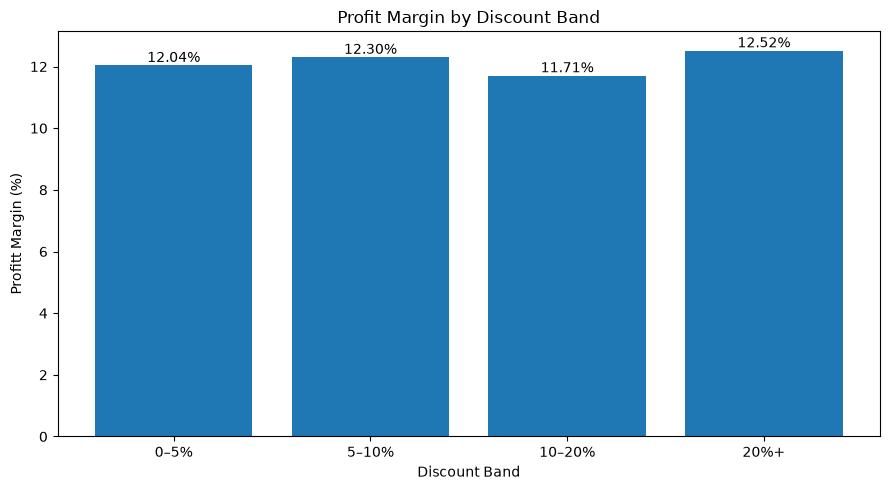

In [4]:
plt.figure(figsize=(9, 5))

bars = plt.bar(
    discount_summary["Discount_Band"].astype(str),
    discount_summary["Profit_Margin_Percent"]
)

plt.title("Profit Margin by Discount Band")
plt.xlabel("Discount Band")
plt.ylabel("Profitt Margin (%)")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()    

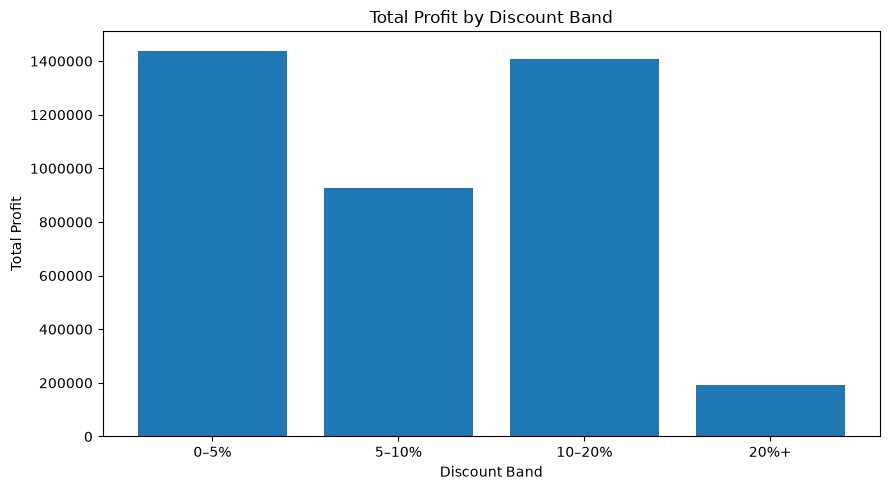

In [5]:
plt.figure(figsize=(9, 5))

plt.bar(
    discount_summary["Discount_Band"].astype(str),
    discount_summary["Total_Profit"]
)

plt.title("Total Profit by Discount Band")
plt.xlabel("Discount Band")
plt.ylabel("Total Profit")
plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()

In [6]:
print("DISCOUNT IMPACT: BUSINESS SUMMARY")
print("-" * 40)

best_profit_band = discount_summary.loc[
    discount_summary["Total_Profit"].idxmax(),
    "Discount_Band"
]

best_margin_band = discount_summary.loc[
    discount_summary["Profit_Margin_Percent"].idxmax(),
    "Discount_Band"
]

print("Highest total profit band:", best_profit_band)
print("Highest profit margin band:", best_margin_band)
print("\nRecommendation:")
print(
    "Review products and transactions in the 20%+ discount band "
    "to understand their lower total profit contribution."
)

DISCOUNT IMPACT: BUSINESS SUMMARY
----------------------------------------
Highest total profit band: 0–5%
Highest profit margin band: 20%+

Recommendation:
Review products and transactions in the 20%+ discount band to understand their lower total profit contribution.


,Discount_Band,Average_Profit_Ratio,Order_Count
0,0–5%,12.21,60171
1,5–10%,12.27,40116
2,10–20%,11.73,70203
3,20–30%,12.72,10029
4,30–40%,NaN,0
5,40–50%,NaN,0
6,50%+,NaN,0


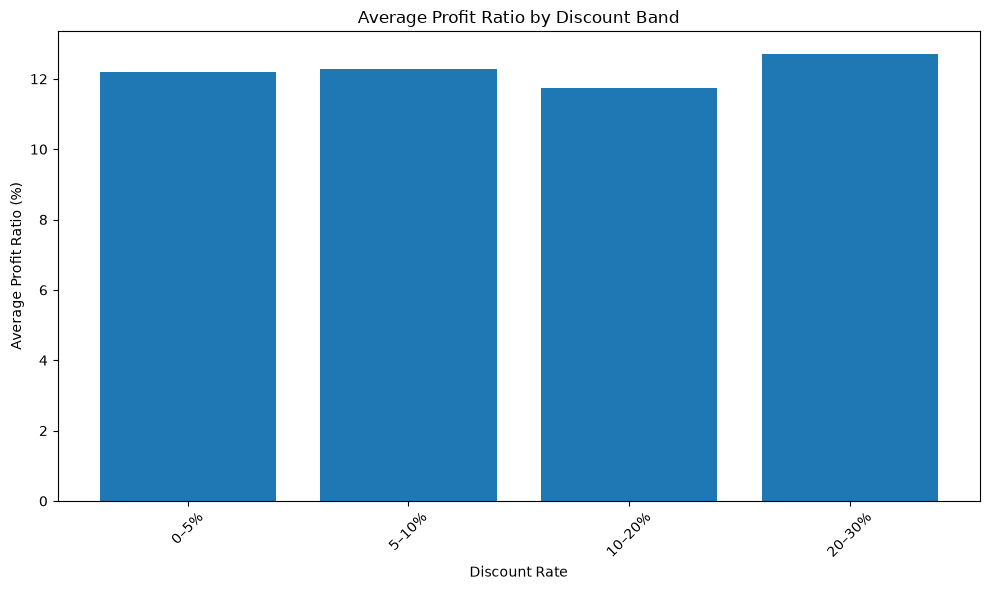

In [1]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

data_path = Path.cwd().parent / "data" / "processed" / "apl_logistics_cleaned.csv"
df = pd.read_csv(data_path)

discount_analysis = df[
    ["Order Item Discount Rate", "Order Item Profit Ratio"]
].dropna().copy()

discount_analysis["Discount_Rate_Percent"] = (
    discount_analysis["Order Item Discount Rate"] * 100
)

discount_analysis["Profit_Ratio_Percent"] = (
    discount_analysis["Order Item Profit Ratio"] * 100
)

discount_analysis["Discount_Band"] = pd.cut(
    discount_analysis["Discount_Rate_Percent"],
    bins=[-0.01, 5, 10, 20, 30, 40, 50, 100],
    labels=["0–5%", "5–10%", "10–20%", "20–30%",
            "30–40%", "40–50%", "50%+"],
    include_lowest=True
)

discount_summary = discount_analysis.groupby(
    "Discount_Band", observed=False
).agg(
    Average_Profit_Ratio=("Profit_Ratio_Percent", "mean"),
    Order_Count=("Profit_Ratio_Percent", "size")
).reset_index()

display(discount_summary.round(2))

plt.figure(figsize=(10, 6))
plt.bar(
    discount_summary["Discount_Band"].astype(str),
    discount_summary["Average_Profit_Ratio"]
)
plt.title("Average Profit Ratio by Discount Band")
plt.xlabel("Discount Rate")
plt.ylabel("Average Profit Ratio (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [2]:
overall_profit_ratio = (
    discount_analysis["Profit_Ratio_Percent"].mean()
)

discount_summary["Profit_Ratio_Difference"] = (
    discount_summary["Average_Profit_Ratio"]
    - overall_profit_ratio
)

discount_summary["Below_Average_Profit_Ratio"] = (
    discount_summary["Average_Profit_Ratio"]
    < overall_profit_ratio
)

print(f"Overall average profit ratio: {overall_profit_ratio:.2f}%")
print("\nDiscount impact diagnostic:")
display(discount_summary.round(2))

erosion_bands = discount_summary[
    discount_summary["Below_Average_Profit_Ratio"]
    & (discount_summary["Order_Count"] > 0)
]

print("\nDiscount bands with below-average profit ratios:")
display(erosion_bands.round(2))


Overall average profit ratio: 12.06%

Discount impact diagnostic:


,Discount_Band,Average_Profit_Ratio,Order_Count,Profit_Ratio_Difference,Below_Average_Profit_Ratio
0,0–5%,12.21,60171,0.14,False
1,5–10%,12.27,40116,0.20,False
2,10–20%,11.73,70203,-0.33,True
3,20–30%,12.72,10029,0.65,False
4,30–40%,NaN,0,NaN,False
5,40–50%,NaN,0,NaN,False
6,50%+,NaN,0,NaN,False



Discount bands with below-average profit ratios:


,Discount_Band,Average_Profit_Ratio,Order_Count,Profit_Ratio_Difference,Below_Average_Profit_Ratio
2,10–20%,11.73,70203,-0.33,True


In [1]:
import pandas as pd
from pathlib import Path

# Load cleaned dataset
file_path = Path.cwd().parent / "data" / "processed" / "apl_logistics_cleaned.csv"
df = pd.read_csv(file_path)

discount_col = "Order Item Discount Rate"
profit_col = "Order Profit Per Order"
margin_col = "Order Item Profit Ratio"

df["Discount Rate (%)"] = df[discount_col] * 100

df["Discount Band"] = pd.cut(
    df["Discount Rate (%)"],
    bins=[-0.01, 5, 10, 15, 20, 30, 50, 100],
    labels=[
        "0–5%", "5–10%", "10–15%", "15–20%",
        "20–30%", "30–50%", "50%+"
    ],
    include_lowest=True
)

discount_summary = (
    df.groupby("Discount Band", observed=False)
    .agg(
        Records=(profit_col, "size"),
        Average_Discount=("Discount Rate (%)", "mean"),
        Average_Profit=(profit_col, "mean"),
        Average_Profit_Ratio=(margin_col, "mean")
    )
    .reset_index()
)

discount_summary["Average_Profit_Ratio (%)"] = (
    discount_summary["Average_Profit_Ratio"] * 100
)

overall_profit_ratio = df[margin_col].mean() * 100

discount_summary["Below Overall Average"] = (
    discount_summary["Average_Profit_Ratio (%)"]
    < overall_profit_ratio
)

print(f"Overall average profit ratio: {overall_profit_ratio:.2f}%")
display(discount_summary.round(2))

Overall average profit ratio: 12.06%


,Discount Band,Records,Average_Discount,Average_Profit,Average_Profit_Ratio,Average_Profit_Ratio (%),Below Overall Average
0,0–5%,60171,2.50,23.92,0.12,12.21,False
1,5–10%,40116,8.00,23.10,0.12,12.27,False
2,10–15%,30087,13.33,20.78,0.12,11.79,True
3,15–20%,40116,17.75,19.54,0.12,11.69,True
4,20–30%,10029,25.00,19.13,0.13,12.72,False
5,30–50%,0,NaN,NaN,NaN,NaN,False
6,50%+,0,NaN,NaN,NaN,NaN,False


In [2]:
# Discount Impact Ratio KPI

gross_sales = df["Sales"].sum()
total_discounts = df["Order Item Discount"].sum()

discount_impact_ratio = (
    total_discounts / gross_sales * 100
    if gross_sales != 0 else 0
)

print(f"Gross Sales: ${gross_sales:,.2f}")
print(f"Total Discounts: ${total_discounts:,.2f}")
print(f"Discount Impact Ratio: {discount_impact_ratio:.2f}%")

Gross Sales: $36,784,734.31
Total Discounts: $3,730,378.40
Discount Impact Ratio: 10.14%
